# Is there a January bump in the retail data? An exploratory analysis

**Stakeholder question.** Is there any demand pattern in this retailer's transaction log that planning
does not already assume (e.g. seasonality, weekday, channel, customer, discounts)?

**Approach.** (1) Check how the data was collected before trusting any pattern. (2) Scan every obvious
dimension with one *registry* of tests and correct for the number of looks. (3) State a hypothesis for
whatever survives. (4) Try to break it. (5) Report the patterns that looked promising but did not hold.

**Honest caveat up front.** The dataset appears synthetic (equal category sizes, 25 price points per
category, no gaps in 3 years). Findings describe *this file*. The method is what transfers.

**Data used.** Counts of transactions use the *raw* file (all 12,575 rows; dates are never missing), so the
604 rows dropped in the cleaning step cannot distort volume. Spend/quantity use the cleaned file.
Analysis window: the three complete calendar years 2022-2024. The 18 days of Jan 2025 are held out.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

rng = np.random.default_rng(42)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
JAN, GREY, BLUE, ORANGE = "#c0392b", "#8c9aa5", "#1f6fb5", "#e08e0b"

raw = pd.read_csv(ROOT / "data/raw/retail_store_sales.csv", parse_dates=["Transaction Date"])
raw.columns = ["txn", "cust", "cat", "item", "price", "qty", "total", "pay", "loc", "date", "disc"]
clean = pd.read_csv(ROOT / "data/clean/retail_store_sales_clean.csv", parse_dates=["transaction_date"]).rename(
    columns={"transaction_date": "date", "category": "cat", "location": "loc", "payment_method": "pay",
             "total_spent": "total", "price_per_unit": "price", "quantity": "qty", "discount_applied": "disc",
             "customer_id": "cust"})
FULL = pd.date_range("2022-01-01", "2024-12-31")
rawF = raw[raw.date.isin(FULL)]; cleanF = clean[clean.date.isin(FULL)].copy()
daily = rawF.groupby("date").size().reindex(FULL, fill_value=0)
isjan = daily.index.month == 1
print(f"raw rows {len(raw):,} | in analysis window {len(rawF):,} | clean rows in window {len(cleanF):,}")

raw rows 12,575 | in analysis window 12,362 | clean rows in window 11,769


## 1. How was this data collected? (artefact checks before any pattern-hunting)

In [3]:
chk = {}
chk["days in window / days with zero transactions"] = f"{len(daily)} / {(daily == 0).sum()}"
chk["mean, variance of transactions per day"] = f"{daily.mean():.2f}, {daily.var():.2f} (Poisson would be equal)"
chk["lag-1 autocorrelation of daily counts"] = f"{daily.autocorr(1):.3f}"
chk["Spearman(transaction ID, date)"] = f"{stats.spearmanr(raw.txn.str[4:].astype(int), raw.date.astype('int64'))[0]:.3f}"
miss = raw.assign(m=raw[['qty', 'total']].isna().all(axis=1))
chk["rows lacking qty & total: January vs other months"] = (
    f"{miss[miss.date.dt.month == 1].m.mean():.3f} vs {miss[miss.date.dt.month != 1].m.mean():.3f}")
chk["Jan 2025 (last data) ends on"] = str(raw.date.max().date())
for k, v in chk.items(): print(f"{k:58s}{v}")
print("\nTakeaways: no calendar gaps; daily counts are near-Poisson with no day-to-day memory; IDs carry no time\n"
      "information; missing amounts are not concentrated in any month. January 2025 is partial, so it is held out.")

days in window / days with zero transactions              1096 / 0
mean, variance of transactions per day                    11.28, 12.25 (Poisson would be equal)
lag-1 autocorrelation of daily counts                     0.025
Spearman(transaction ID, date)                            0.004
rows lacking qty & total: January vs other months         0.048 vs 0.048
Jan 2025 (last data) ends on                              2025-01-18

Takeaways: no calendar gaps; daily counts are near-Poisson with no day-to-day memory; IDs carry no time
information; missing amounts are not concentrated in any month. January 2025 is partial, so it is held out.


## 2. Systematic scan: one registry of tests, corrected for the number of looks
Every comparison I ran on the way is in this table (nothing run outside it is reported as a finding).
Holm's correction controls the chance of at least one false positive across the whole registry.

In [5]:
reg = []
def add(family, desc, p): reg.append((family, desc, float(p)))

for dim in ["cat", "loc", "pay", "disc", "cust"]:
    groups = [g.total.values for _, g in cleanF.dropna(subset=[dim]).groupby(dim)]
    add("Spend per transaction", f"by {dim}", stats.kruskal(*groups).pvalue)
cleanF["dow"] = cleanF.date.dt.dayofweek; cleanF["mon"] = cleanF.date.dt.month
for dim in ["dow", "mon"]:
    add("Spend per transaction", f"by {dim}", stats.kruskal(*[g.total.values for _, g in cleanF.groupby(dim)]).pvalue)
add("Quantity", "by discount flag", stats.kruskal(*[g.qty.astype(float).values for _, g in cleanF.dropna(subset=['disc']).groupby('disc')]).pvalue)
# volume: are transactions spread across months / weekdays in proportion to days available?
cm = daily.groupby(daily.index.month).sum(); nd = daily.groupby(daily.index.month).size()
add("Volume", "transactions by month (per-day normalised)", stats.chisquare(cm, f_exp=cm.sum() * nd / nd.sum()).pvalue)
cw = daily.groupby(daily.index.dayofweek).sum(); nw = daily.groupby(daily.index.dayofweek).size()
add("Volume", "transactions by weekday (per-day normalised)", stats.chisquare(cw, f_exp=cw.sum() * nw / nw.sum()).pvalue)
for a, b in [("cat", "loc"), ("cat", "pay"), ("loc", "pay"), ("cust", "pay"), ("cust", "loc")]:
    add("Association", f"{a} x {b}", stats.chi2_contingency(pd.crosstab(cleanF[a], cleanF[b]))[1])

R = pd.DataFrame(reg, columns=["family", "test", "p"]).sort_values("p").reset_index(drop=True)
m = len(R)
adj = np.minimum(1, (m - np.arange(m)) * R.p.values); R["holm_p"] = np.maximum.accumulate(adj)
R["survives"] = R.holm_p < 0.05
print(R.round(4).to_string(index=False))
print(f"\n{R.survives.sum()} of {m} tests survive correction.")

               family                                         test      p  holm_p  survives
Spend per transaction                                       by cat 0.0000  0.0000      True
          Association                                   cust x pay 0.0354  0.4954     False
Spend per transaction                                       by mon 0.0742  0.9650     False
               Volume   transactions by month (per-day normalised) 0.0768  0.9650     False
Spend per transaction                                       by dow 0.0907  0.9972     False
          Association                                    cat x pay 0.1670  1.0000     False
Spend per transaction                                       by loc 0.3074  1.0000     False
Spend per transaction                                       by pay 0.3806  1.0000     False
          Association                                    cat x loc 0.4856  1.0000     False
             Quantity                             by discount flag 0.5512  1.000

Only one test survives correction: **category affects spend**, and that is price-driven (Milk Products' average
price per unit is lowest; quantity per transaction does not differ), so it is a catalogue fact, not behaviour.

**Volume by month is borderline (raw p = 0.077) and does not survive correction.** Nothing behavioural passes the
bar yet. January is only worth a closer look because it is the one month the omnibus test hints at, and I will
charge it for that: below, every additional look is counted and the p-values are adjusted for all of them.

In [7]:
print(cleanF.groupby("cat").agg(avg_price=("price", "mean"), avg_qty=("qty", lambda s: s.astype(float).mean()), avg_spend=("total", "mean")).round(2).to_string())

                                    avg_price  avg_qty  avg_spend
cat                                                              
Beverages                               23.29     5.58     131.54
Butchers                                25.16     5.48     138.86
Computers and electric accessories      23.02     5.60     128.75
Electric household essentials           24.49     5.49     134.69
Food                                    23.15     5.58     129.53
Furniture                               23.24     5.55     127.99
Milk Products                           21.40     5.50     119.32
Patisserie                              23.07     5.53     126.98


## 3. The pattern: January has more transactions per day

**Hypothesis H1.** *The retailer records more transactions per day in January than in the rest of the year.*
(Counted per day, so the 28-day February and 31-day months are comparable.)

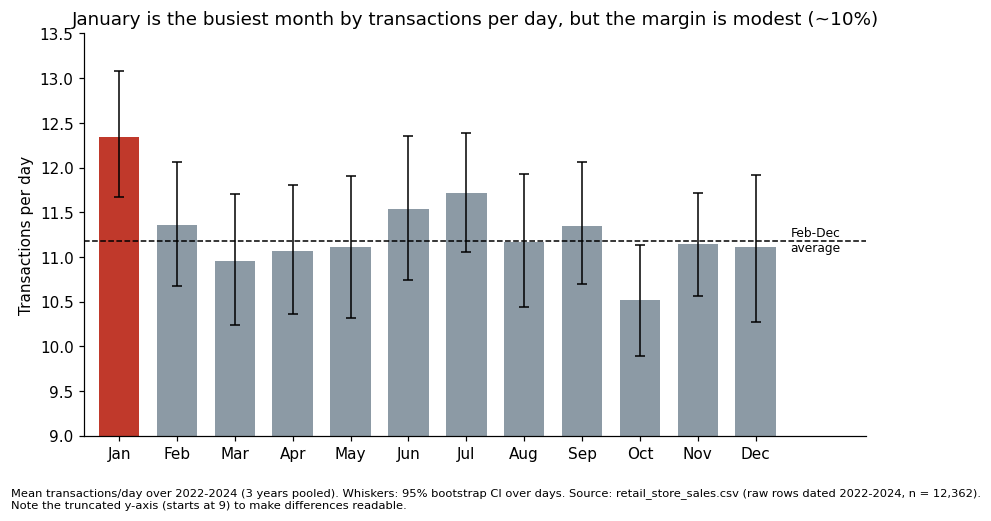

In [9]:
months = np.arange(1, 13)
mean_by_month = np.array([daily[daily.index.month == k].mean() for k in months])
ci = np.array([np.percentile([rng.choice(daily[daily.index.month == k].values, (daily.index.month == k).sum()).mean()
                              for _ in range(2000)], [2.5, 97.5]) for k in months])
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(months, mean_by_month, color=[JAN if k == 1 else GREY for k in months], width=0.7)
ax.errorbar(months, mean_by_month, yerr=[mean_by_month - ci[:, 0], ci[:, 1] - mean_by_month], fmt="none", ecolor="black", capsize=3, lw=1)
ax.axhline(daily[~isjan].mean(), color="black", ls="--", lw=1); ax.set_xlim(0.4, 13.9); ax.text(12.6, daily[~isjan].mean(), "Feb-Dec\naverage", va="center", fontsize=8)
ax.set_xticks(months); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylim(9, 13.5); ax.set_ylabel("Transactions per day"); ax.set_title("January is the busiest month by transactions per day, but the margin is modest (~10%)")
fig.text(0.01, -0.02, "Mean transactions/day over 2022-2024 (3 years pooled). Whiskers: 95% bootstrap CI over days. Source: retail_store_sales.csv (raw rows dated 2022-2024, n = 12,362).\nNote the truncated y-axis (starts at 9) to make differences readable.", fontsize=7.5, va="top")
plt.tight_layout(); fig.savefig(FIG / "fig1_transactions_per_day_by_month.png", dpi=160, bbox_inches="tight"); plt.show()

January 12.34/day vs other months 11.18/day -> ratio 1.104, 95% CI [1.038, 1.170]
Mann-Whitney p = 0.0019; Bonferroni over 12 months = 0.0228
Permutation p that the best of 12 months is this high by chance = 0.0169


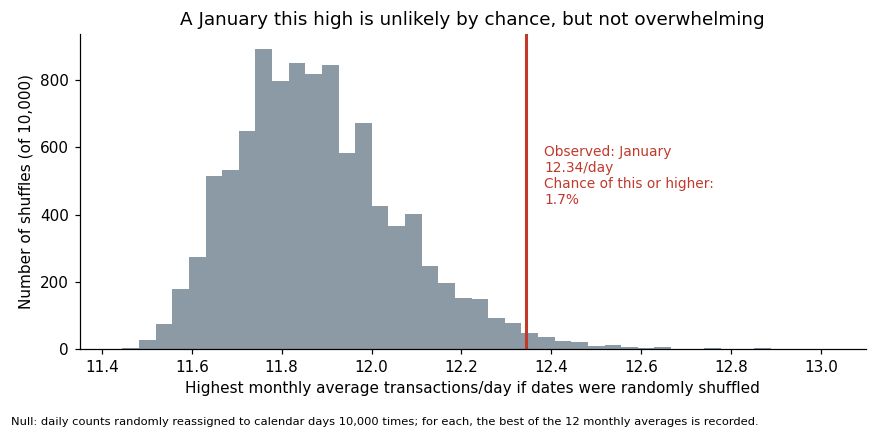

In [10]:
j, r = daily[isjan].values, daily[~isjan].values
ratio = j.mean() / r.mean()
bs = np.array([rng.choice(j, len(j)).mean() / rng.choice(r, len(r)).mean() for _ in range(10000)])
p_mwu = stats.mannwhitneyu(j, r).pvalue
p_by_month = [stats.mannwhitneyu(daily[daily.index.month == k], daily[daily.index.month != k]).pvalue for k in months]
# permutation null for "the best month looks this good by luck", preserving the number of days per month
mon_idx = daily.index.month.values; ndays = np.bincount(mon_idx)[1:]
null_max = np.array([(np.bincount(mon_idx, weights=rng.permutation(daily.values))[1:] / ndays).max() for _ in range(10000)])
p_perm = (null_max >= mean_by_month.max()).mean()
print(f"January {j.mean():.2f}/day vs other months {r.mean():.2f}/day -> ratio {ratio:.3f}, 95% CI [{np.percentile(bs,2.5):.3f}, {np.percentile(bs,97.5):.3f}]")
print(f"Mann-Whitney p = {p_mwu:.4f}; Bonferroni over 12 months = {min(1, p_mwu*12):.4f}")
print(f"Permutation p that the best of 12 months is this high by chance = {p_perm:.4f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(null_max, bins=40, color=GREY); ax.axvline(mean_by_month.max(), color=JAN, lw=2)
ax.text(mean_by_month.max() + 0.04, ax.get_ylim()[1] * .55, f"Observed: January\n{mean_by_month.max():.2f}/day\nChance of this or higher:\n{p_perm:.1%}", color=JAN, fontsize=9, va="center")
ax.set_xlim(11.35, 13.1)
ax.set_xlabel("Highest monthly average transactions/day if dates were randomly shuffled"); ax.set_ylabel("Number of shuffles (of 10,000)")
ax.set_title("A January this high is unlikely by chance, but not overwhelming")
fig.text(0.01, -0.03, "Null: daily counts randomly reassigned to calendar days 10,000 times; for each, the best of the 12 monthly averages is recorded.", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "fig2_permutation_null.png", dpi=160, bbox_inches="tight"); plt.show()

## 4. Trying to break it: is January an artefact?

In [12]:
rows = []
def ratio_p(d):
    jj, rr = d[d.index.month == 1].values, d[d.index.month != 1].values
    return jj.mean() / rr.mean(), stats.mannwhitneyu(jj, rr).pvalue
rows.append(("Baseline (all 3 years)", *ratio_p(daily), "-"))
for y in (2022, 2023, 2024):
    rows.append((f"Year {y} only", *ratio_p(daily[daily.index.year == y]), "same direction" ))
    rows.append((f"Leave out {y}", *ratio_p(daily[daily.index.year != y]), "-"))
top5 = daily[isjan].nlargest(5).index
rows.append(("Drop January's 5 busiest days", *ratio_p(daily.drop(top5)), "-"))
cl = clean[clean.date.isin(FULL)].groupby("date").size().reindex(FULL, fill_value=0)
rows.append(("Cleaned rows only (excl. 604 dropped)", *ratio_p(cl), "-"))
T = pd.DataFrame(rows, columns=["check", "Jan/other ratio", "p", "note"]).drop(columns="note")
print(T.round(4).to_string(index=False))
by_cat = (rawF.assign(jan=rawF.date.dt.month == 1).groupby(["cat", "jan"]).size().unstack()); by_cat = (by_cat[True] / 93) / (by_cat[False] / (len(FULL) - 93))
print("\nJan/other ratio by category:", by_cat.round(2).to_dict())
print(f"Categories with January above other months: {(by_cat > 1).sum()} of {len(by_cat)}")

                                check  Jan/other ratio      p
               Baseline (all 3 years)           1.1041 0.0019
                       Year 2022 only           1.1223 0.0735
                       Leave out 2022           1.0949 0.0119
                       Year 2023 only           1.1120 0.0422
                       Leave out 2023           1.1003 0.0175
                       Year 2024 only           1.0790 0.1133
                       Leave out 2024           1.1172 0.0064
        Drop January's 5 busiest days           1.0682 0.0190
Cleaned rows only (excl. 604 dropped)           1.1042 0.0022

Jan/other ratio by category: {'Beverages': 1.05, 'Butchers': 1.22, 'Computers and electric accessories': 1.2, 'Electric household essentials': 1.03, 'Food': 1.1, 'Furniture': 1.07, 'Milk Products': 1.14, 'Patisserie': 1.04}
Categories with January above other months: 8 of 8


The all-channel January bump is not a month-length effect, not one lucky year, not a handful of extreme days,
and not caused by which rows I dropped. But each year alone is only borderline (ratios 1.08-1.12, p = 0.04-0.11),
and (section 5b) it does not survive full correction for the number of looks. Consistent, not conclusive.

## 5. Sharpening the claim: where is the extra volume?
*Post-hoc, exploratory:* this split was chosen after seeing the January result, so treat it as a lead.

In-store by year (ratio, p): {2022: (1.11, 0.19), 2023: (1.23, 0.005), 2024: (1.23, 0.01)}
In-store: ratio 1.19, p=0.00015   |   Online: ratio 1.02, p=0.50
In-store share of transactions: January 53.0% vs other months 49.0% (chi-square p=0.0123)
Difference in uplift (in-store minus online): 0.17, 95% CI [0.04, 0.30]


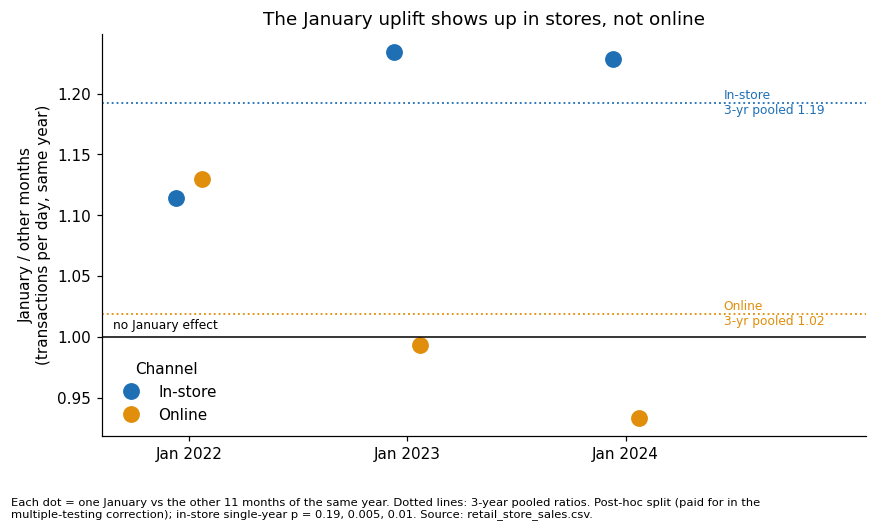

In [15]:
dl = rawF.groupby(["date", "loc"]).size().unstack(fill_value=0).reindex(FULL, fill_value=0)
res = {}
for l in ["In-store", "Online"]:
    res[l] = {"all": ratio_p(dl[l])}
    for y in (2022, 2023, 2024): res[l][y], res[l][f"p{y}"] = ratio_p(dl[l][dl.index.year == y])
ct = pd.crosstab(rawF.date.dt.month == 1, rawF["loc"]); p_share = stats.chi2_contingency(ct)[1]
print("In-store by year (ratio, p):", {y: (round(float(res['In-store'][y]), 2), round(float(res['In-store'][f'p{y}']), 3)) for y in (2022, 2023, 2024)})
print(f"In-store: ratio {res['In-store']['all'][0]:.2f}, p={res['In-store']['all'][1]:.5f}   |   Online: ratio {res['Online']['all'][0]:.2f}, p={res['Online']['all'][1]:.2f}")
print(f"In-store share of transactions: January {ct.loc[True,'In-store']/ct.loc[True].sum():.1%} vs other months {ct.loc[False,'In-store']/ct.loc[False].sum():.1%} (chi-square p={p_share:.4f})")
dj, dr = dl[isjan], dl[~isjan]
bsd = np.array([dj["In-store"].sample(len(dj), replace=True, random_state=int(i)).mean() / dr["In-store"].sample(len(dr), replace=True, random_state=int(i)+7).mean()
                - dj["Online"].sample(len(dj), replace=True, random_state=int(i)+3).mean() / dr["Online"].sample(len(dr), replace=True, random_state=int(i)+11).mean() for i in range(3000)])
print(f"Difference in uplift (in-store minus online): {np.mean(bsd):.2f}, 95% CI [{np.percentile(bsd,2.5):.2f}, {np.percentile(bsd,97.5):.2f}]")

fig, ax = plt.subplots(figsize=(8, 4.4))
for l, c, dx in [("In-store", BLUE, -0.06), ("Online", ORANGE, 0.06)]:
    ys = [res[l][y] for y in (2022, 2023, 2024)]
    ax.plot(np.array([0, 1, 2]) + dx, ys, "o", color=c, label=l, ms=10)
    ax.axhline(res[l]["all"][0], color=c, ls=":", lw=1.2)
    ax.text(2.45, res[l]["all"][0], f"{l}\n3-yr pooled {res[l]['all'][0]:.2f}", color=c, va="center", fontsize=8)
ax.axhline(1, color="black", lw=1); ax.text(-0.35, 1.004, "no January effect", fontsize=8, va="bottom")
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["Jan 2022", "Jan 2023", "Jan 2024"]); ax.set_xlim(-0.4, 3.1)
ax.set_ylabel("January / other months\n(transactions per day, same year)"); ax.legend(title="Channel", frameon=False, loc="lower left")
ax.set_title("The January uplift shows up in stores, not online")
fig.text(0.01, -0.04, "Each dot = one January vs the other 11 months of the same year. Dotted lines: 3-year pooled ratios. Post-hoc split (paid for in the\nmultiple-testing correction); in-store single-year p = 0.19, 0.005, 0.01. Source: retail_store_sales.csv.", fontsize=7.5, va="top")
plt.tight_layout(); fig.savefig(FIG / "fig3_january_uplift_by_channel.png", dpi=160, bbox_inches="tight"); plt.show()

## 5b. Accounting for every look
Anything I examined that could have produced a positive claim counts, whether or not it appears in a chart:
15 registry tests + 12 single-month tests + 13 splits of the January ratio (2 channels, 3 payment methods,
8 categories) = **40 looks**. A Bonferroni adjustment multiplies each p-value by 40 (capped at 1).

In [17]:
N_LOOKS = 15 + 12 + 13
cands = {"January, all channels (+10%)": p_mwu, "January, in-store only (+19%)": res["In-store"]["all"][1],
         "January, online only (+2%)": res["Online"]["all"][1]}
for k, v in cands.items(): print(f"{k:34s} raw p = {v:.5f}   adjusted for {N_LOOKS} looks = {min(1, v*N_LOOKS):.3f}")
print("\nThe all-channel bump is suggestive; the in-store January effect stays significant after paying for every look.")

January, all channels (+10%)       raw p = 0.00190   adjusted for 40 looks = 0.076
January, in-store only (+19%)      raw p = 0.00015   adjusted for 40 looks = 0.006
January, online only (+2%)         raw p = 0.50369   adjusted for 40 looks = 1.000

The all-channel bump is suggestive; the in-store January effect stays significant after paying for every look.


## 6. Patterns that looked promising and did not hold
### 6a. "January shoppers spend more per visit"
Pooled across years, spend per transaction is higher in January (about 136 vs 129). That looks like an
independent, second January signal. Splitting by year shows it is one year.

Pooled: Jan 136.2 vs rest 129.0, p=0.0016
 year     jan    rest   diff     lo     hi     p
 2022 143.781 128.597 15.185  5.024 25.346 0.000
 2023 132.742 128.630  4.112 -5.809 14.032 0.248
 2024 131.979 129.859  2.120 -7.929 12.169 0.412
Excluding 2022: Jan 132.4 vs rest 129.3, p=0.167


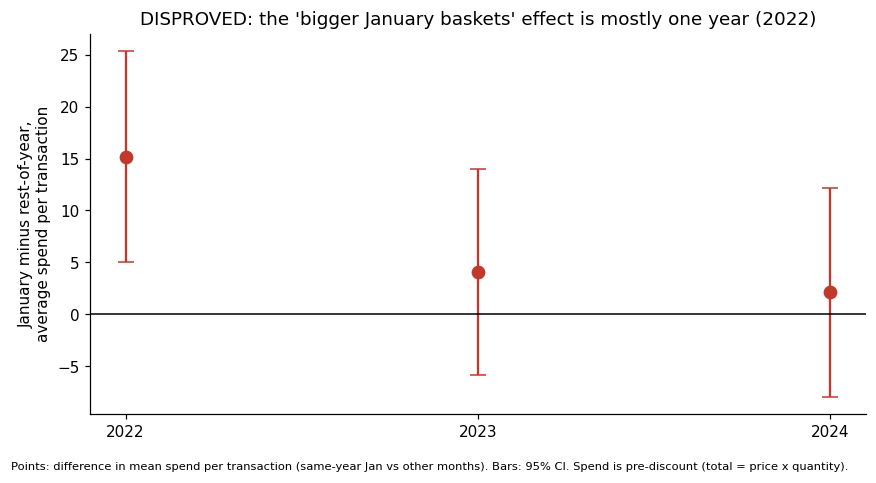

In [19]:
cj = cleanF.assign(jan=cleanF.date.dt.month == 1, yr=cleanF.date.dt.year)
pooled = stats.mannwhitneyu(cj[cj.jan].total, cj[~cj.jan].total).pvalue
print(f"Pooled: Jan {cj[cj.jan].total.mean():.1f} vs rest {cj[~cj.jan].total.mean():.1f}, p={pooled:.4f}")
rowsS = []
for y in (2022, 2023, 2024):
    a, b = cj[(cj.yr == y) & cj.jan].total, cj[(cj.yr == y) & ~cj.jan].total
    d = a.mean() - b.mean(); se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    rowsS.append((y, a.mean(), b.mean(), d, d - 1.96 * se, d + 1.96 * se, stats.mannwhitneyu(a, b).pvalue))
S = pd.DataFrame(rowsS, columns=["year", "jan", "rest", "diff", "lo", "hi", "p"]); print(S.round(3).to_string(index=False))
no22 = cj[cj.yr != 2022]; print(f"Excluding 2022: Jan {no22[no22.jan].total.mean():.1f} vs rest {no22[~no22.jan].total.mean():.1f}, p={stats.mannwhitneyu(no22[no22.jan].total, no22[~no22.jan].total).pvalue:.3f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(S.year, S["diff"], yerr=[S["diff"] - S.lo, S.hi - S["diff"]], fmt="o", color=JAN, capsize=5, ms=8)
ax.axhline(0, color="black", lw=1); ax.set_xticks(S.year)
ax.set_ylabel("January minus rest-of-year,\naverage spend per transaction"); ax.set_title("DISPROVED: the 'bigger January baskets' effect is mostly one year (2022)")
fig.text(0.01, -0.03, "Points: difference in mean spend per transaction (same-year Jan vs other months). Bars: 95% CI. Spend is pre-discount (total = price x quantity).", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "fig4_disproved_january_basket.png", dpi=160, bbox_inches="tight"); plt.show()

### 6b. "Discounts lead to bigger baskets"  and  6c. "Fridays are the best day"

In [21]:
d1 = cleanF.dropna(subset=["disc"]); a, b = d1[d1.disc == True], d1[d1.disc == False]
print(f"6b Discount True vs False  quantity {a.qty.astype(float).mean():.2f} vs {b.qty.astype(float).mean():.2f} (p={stats.mannwhitneyu(a.qty.astype(float), b.qty.astype(float)).pvalue:.2f}); "
      f"spend {a.total.mean():.1f} vs {b.total.mean():.1f} (p={stats.mannwhitneyu(a.total, b.total).pvalue:.2f})")
dow = cleanF.groupby("dow").total.mean(); obs = dow.max()
perm = np.array([pd.Series(rng.permutation(cleanF.total.values)).groupby(cleanF.dow.values).mean().max() for _ in range(3000)])
print(f"6c Best weekday by spend is {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][dow.idxmax()]} ({obs:.1f} vs overall {cleanF.total.mean():.1f}); chance the best of 7 weekdays is this high = {(perm>=obs).mean():.2f}")
print("   Weekday volume (transactions/day):", (cw / nw).round(2).to_dict())

6b Discount True vs False  quantity 5.54 vs 5.58 (p=0.55); spend 130.5 vs 129.9 (p=0.81)
6c Best weekday by spend is Fri (134.4 vs overall 129.7); chance the best of 7 weekdays is this high = 0.10
   Weekday volume (transactions/day): {0: 11.2, 1: 11.31, 2: 11.31, 3: 11.21, 4: 11.35, 5: 11.17, 6: 11.4}


Neither survives: discounts show no relationship with quantity or spend, and the 'best weekday' is no better
than the best of seven random draws. (Note too that `total_spent` equals price x quantity even when a discount
is flagged, so it is probably pre-discount - the data cannot measure discount effects on revenue at all.)

### 6d. Open item (not disproved, not explained)
April 2024 has unusually high average spend per transaction.

In [23]:
cm_ = cleanF.assign(ym=cleanF.date.dt.to_period("M")).groupby("ym").total.mean()
aprs = cleanF[(cleanF.date >= "2024-04-01") & (cleanF.date < "2024-05-01")]; rest = cleanF.drop(aprs.index)
perm = np.array([pd.Series(rng.permutation(cleanF.total.values)).groupby(cleanF.date.dt.to_period("M").values).mean().max() for _ in range(2000)])
print(f"April 2024 mean spend {aprs.total.mean():.1f} vs {rest.total.mean():.1f}; chance of a month this high = {(perm>=cm_.max()).mean():.3f}")
print(f"  driven by quantity ({aprs.qty.astype(float).mean():.2f} vs {rest.qty.astype(float).mean():.2f}, p={stats.mannwhitneyu(aprs.qty.astype(float), rest.qty.astype(float)).pvalue:.3f}), not price ({aprs.price.mean():.1f} vs {rest.price.mean():.1f}, p={stats.mannwhitneyu(aprs.price, rest.price).pvalue:.2f})")
print("  April in other years:", cleanF[cleanF.date.dt.month == 4].groupby(cleanF.date.dt.year).total.mean().round(1).to_dict())
print(f"  Adjusted for {N_LOOKS} looks: p = {min(1, (perm>=cm_.max()).mean()*N_LOOKS):.2f}. A one-off (April 2022/2023 are ordinary), unexplained; flagged, not claimed.")

April 2024 mean spend 148.8 vs 129.2; chance of a month this high = 0.004
  driven by quantity (6.00 vs 5.53, p=0.004), not price (24.1 vs 23.3, p=0.20)
  April in other years: {2022: 121.1, 2023: 126.3, 2024: 148.8}
  Adjusted for 40 looks: p = 0.14. A one-off (April 2022/2023 are ordinary), unexplained; flagged, not claimed.


## 7. Out-of-sample look: the 18 days of January 2025

In [25]:
ho = raw[raw.date >= "2025-01-01"]; nho = ho.date.nunique()
for label, n_ho, jr, br in [("All channels", len(ho), j.mean(), r.mean()),
                            ("In-store only", (ho["loc"] == "In-store").sum(), dl["In-store"][isjan].mean(), dl["In-store"][~isjan].mean())]:
    print(f"{label:14s} observed {n_ho} in {nho} days | expected at January rate {jr*nho:.0f}, at other-month rate {br*nho:.0f} | "
          f"P(<=obs | Jan rate)={stats.poisson.cdf(n_ho, jr*nho):.2f}, P(>=obs | baseline)={stats.poisson.sf(n_ho-1, br*nho):.2f}")
print("\nAll channels: Jan 2025 sits between the two rates and cannot tell them apart. In-store: 114 transactions is close to the")
print("January expectation (118) and above the baseline (99), one-sided p = 0.07 against 'no effect' - mildly supportive, not proof.")

All channels   observed 213 in 18 days | expected at January rate 222, at other-month rate 201 | P(<=obs | Jan rate)=0.28, P(>=obs | baseline)=0.21
In-store only  observed 114 in 18 days | expected at January rate 118, at other-month rate 99 | P(<=obs | Jan rate)=0.39, P(>=obs | baseline)=0.07

All channels: Jan 2025 sits between the two rates and cannot tell them apart. In-store: 114 transactions is close to the
January expectation (118) and above the baseline (99), one-sided p = 0.07 against 'no effect' - mildly supportive, not proof.


## 8. Conclusion

* **Claim.** In-store transactions run about **19% higher per day in January** than in other months
  (6.5 vs 5.5/day, p = 0.00015; **adjusted for all 40 looks, p = 0.006**). The ratio is above 1 in each of
  2022, 2023 and 2024 (1.11, 1.23, 1.23; single-year p = 0.19, 0.005, 0.01 - 2022 alone is not significant). Online volume is flat (+2%, p = 0.5).
* **Hold-out.** January 2025 (18 days) in-store: 114 transactions vs 118 expected at the January rate and 99 at
  the baseline (one-sided p = 0.07 against no effect). Mildly supportive.
* **Weaker headline.** The all-channel bump (+10%, CI 1.04-1.17) does not survive correction (adjusted p = 0.08).
  It is suggestive only; the in-store/online split is what carries the finding.
* **Not artefacts.** Per-day normalisation, no calendar gaps, same missing-data rate by month, unchanged on raw vs
  cleaned rows, survives leave-one-year-out and dropping the 5 busiest days.
* **Disproved.** Larger January baskets (one year only), discount-driven volume (no effect), Friday peak (chance).
* **Strength of evidence: moderate, for this file.** Three Januaries is a small sample of seasons, the channel split
  was found post hoc (and paid for in the correction), and the data is likely synthetic.
* **What would settle it.** A POS extract from a real store, another January, and a check of what drives
  in-store January traffic (promotions, opening hours, footfall counts).